In [36]:
#Importing necessary libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_curve, auc 

from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

from numpy import loadtxt
import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Going to use these 5 base models for the stacking
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, 
                              GradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.model_selection import KFold

from sklearn.naive_bayes import GaussianNB

import lightgbm as lgb
from sklearn.metrics import mean_squared_error

import matplotlib as mpl
from matplotlib import colors
from scipy import linalg
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [37]:
import pandas as pd

train = pd.read_csv('./train_data.csv')
test = pd.read_csv('./test_data.csv')

train.output.value_counts()  

output
1    3873
0     711
Name: count, dtype: int64

In [38]:
# Read and load the training and test data
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

try:
    sample_solution = pd.read_csv("sample_solution.csv")
except:
    sample_solution = None

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())

Train shape: (4584, 670)
Test shape : (1732, 669)


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,z217,z218,z219,z220,z221,z222,subject,phase,state,output
0,0,0,0,1,-323.106605,2.694366,-1.987520,261.092784,0.013704,0.000100,...,-0.004930,-0.005554,5.246375,-7.534092,3.530736,-0.539045,K,3,C,1
1,0,0,0,1,-376.084691,0.969696,-6.933765,355.311648,0.030292,-0.000153,...,0.022757,0.052506,-3.727741,-2.854443,-0.699268,-0.054074,A,4,C,1
2,0,0,0,0,91.955425,2.621643,-2.581162,51.357206,0.036668,-0.000104,...,-0.086813,-0.101497,-7.510594,19.564182,-17.008130,4.945392,D,3,C,1
3,0,0,0,1,-391.814586,1.866914,-2.510799,382.900317,0.007947,-0.000028,...,0.030856,-0.161398,-6.435819,2.174453,-0.153956,-0.003958,G,2,C,0
4,0,0,0,0,-363.823732,2.951346,-3.726368,330.527539,0.010074,-0.000004,...,-0.017226,-0.016454,-2.581403,3.011932,-1.281361,0.192647,C,2,C,1


In [39]:
# Training Data information
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4584 entries, 0 to 4583
Columns: 670 entries, x1 to output
dtypes: float64(474), int64(194), str(2)
memory usage: 23.4 MB


In [40]:
# Identify numerical and categorical columns

print("\nColumns:")
print(train.columns.tolist())

# Missing values:
print("\nMissing values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

# Unique values
print("\nUnique values:")
display(train.nunique().sort_values())


Columns:
['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39', 'x40', 'x41', 'x42', 'x43', 'x44', 'x45', 'x46', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x53', 'x54', 'x55', 'x56', 'x57', 'x58', 'x59', 'x60', 'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x73', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x80', 'x81', 'x82', 'x83', 'x84', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94', 'x95', 'x96', 'x97', 'x98', 'x99', 'x100', 'x101', 'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x109', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x117', 'x118', 'x119', 'x120', 'x121', 'x122', 'x123', 'x124', 'x125', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x133', 'x134', 'x135', 'x136', 'x137', '

x1      0
y219    0
y221    0
y222    0
z1      0
z2      0
z3      0
z4      0
z5      0
z6      0
z7      0
z8      0
z9      0
z10     0
z11     0
z12     0
z13     0
z14     0
z15     0
y220    0
dtype: int64


Unique values:


x1         1
y57        1
y72        1
y73        1
y74        1
        ... 
y60     4584
y61     4584
y62     4584
y19     4584
y161    4584
Length: 670, dtype: int64

Class distribution:
output
1    3873
0     711
Name: count, dtype: int64

Class percentages:
output
1    84.489529
0    15.510471
Name: proportion, dtype: float64


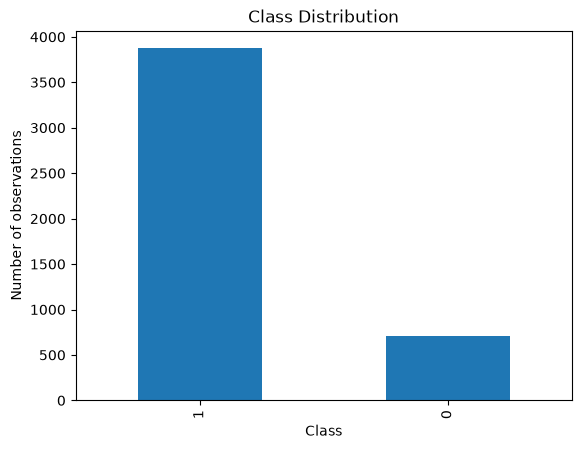

In [41]:
##Checking the class distribution and imbalance in the training data

print("Class distribution:")
print(train['output'].value_counts())

print("\nClass percentages:")
print(train['output'].value_counts(normalize=True) * 100)

train['output'].value_counts().plot(
    kind='bar',
    title='Class Distribution'
)

plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()

In [42]:
# Separate features and target of the training data
X = train.drop(columns=['output'])
y = train['output']

# Stratified train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape)
print("Validation observations:", X_val.shape)

Training observations: (3667, 669)
Validation observations: (917, 669)


In [43]:
# Identify numerical and categorical columns
from sklearn.compose import ColumnTransformer

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()


# Numeric preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

/var/folders/c3/1xdc_j3d5gnbhhnvrtwj5c540000gn/T/ipykernel_51303/3195068650.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [44]:
import numpy as np
import pandas as pd
import shap

from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

In [45]:
xgb_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', XGBClassifier(
        n_estimators=400,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective='binary:logistic',
        eval_metric='auc',
        tree_method='hist',
        random_state=42,
        n_jobs=2
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [46]:
processor = xgb_model.named_steps['preprocessor']
classifier = xgb_model.named_steps['classifier']

X_train_processed = processor.transform(X_train)
X_val_processed = processor.transform(X_val)

explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_train_processed)

shap_importance = np.abs(shap_values).mean(axis=0)

In [47]:
top_features = np.argsort(shap_importance)[-50:]

X_train_shap = X_train_processed[:, top_features]
X_val_shap = X_val_processed[:, top_features]

print("Selected Features:", len(top_features))

Selected Features: 50


In [48]:
shap_xgb = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    reg_alpha=1,
    reg_lambda=10,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=2
)

shap_xgb.fit(X_train_shap, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.85
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [49]:
baseline_preds = xgb_model.predict_proba(X_val)[:, 1]

shap_preds = shap_xgb.predict_proba(X_val_shap)[:, 1]

print("Baseline ROC-AUC:",
      roc_auc_score(y_val, baseline_preds))

print("SHAP XGBoost ROC-AUC:",
      roc_auc_score(y_val, shap_preds))

Baseline ROC-AUC: 0.8550749659245797
SHAP XGBoost ROC-AUC: 0.8469150386188097


In [50]:
# Fit preprocessing on all labeled data
final_processor = clone(preprocessor)

X_full = final_processor.fit_transform(X)

test_1 = test.reindex(columns=X.columns)
X_test = final_processor.transform(test_1)

# Recalculate SHAP feature importance using full training data
ranking_model = clone(classifier)
ranking_model.fit(X_full, y)

final_explainer = shap.TreeExplainer(ranking_model)
final_shap = final_explainer.shap_values(X_full)

final_importance = np.abs(final_shap).mean(axis=0)
final_top_features = np.argsort(final_importance)[-50:]

# Retrain final model
final_model = clone(shap_xgb)

final_model.fit(
    X_full[:, final_top_features],
    y
)

test_probs = final_model.predict_proba(
    X_test[:, final_top_features]
)[:, 1]

In [51]:
sample_solution = pd.read_csv(
    "sample_solution.csv"
)

submission = sample_solution.copy()

submission["output"] = test_probs

submission.to_csv(
    "xgboost_shap_submission.csv",
    index=False
)

print(submission.head())
print("Submission shape:", submission.shape)

   id    output
0   0  0.910014
1   1  0.917869
2   2  0.841883
3   3  0.781148
4   4  0.901500
Submission shape: (1732, 2)
